# 01 – NumPy

Création de tableaux, reshape, indexation, slicing, broadcasting, produit matriciel et tracé Matplotlib.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Créer des tableaux

In [2]:
a = np.array([1, 2, 3, 4, 5, 6])
z = np.zeros((2, 3))
rng = np.random.default_rng(42)
r = rng.random((2, 3))   # équivalent moderne de np.random.rand(2, 3)
r2 = np.random.rand(2, 3)

print("array :", a, a.shape, a.dtype)
print("zeros :\n", z)
print("rand  :\n", r)
print("np.random.rand :\n", r2)

array : [1 2 3 4 5 6] (6,) int64
zeros :
 [[0. 0. 0.]
 [0. 0. 0.]]
rand  :
 [[0.77395605 0.43887844 0.85859792]
 [0.69736803 0.09417735 0.97562235]]
np.random.rand :
 [[0.21309202 0.67315128 0.77756861]
 [0.36611769 0.52815966 0.54413391]]


## 2. Reshape, indexation et slicing

In [3]:
m = np.arange(12).reshape(3, 4)
print(m, m.shape)
print("reshape (4, 3) :\n", m.reshape(4, 3))
print("reshape (2, -1) :\n", m.reshape(2, -1))   # -1 : dimension déduite
print("flatten :", m.flatten())

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] (3, 4)
reshape (4, 3) :
 [[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]
reshape (2, -1) :
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]
flatten : [ 0  1  2  3  4  5  6  7  8  9 10 11]


In [4]:
print("m[1, 2]      =", m[1, 2])        # un élément
print("m[0]         =", m[0])           # première ligne
print("m[:, 1]      =", m[:, 1])        # deuxième colonne
print("m[1:, :2]    =\n", m[1:, :2])    # sous-matrice
print("m[::2, ::2]  =\n", m[::2, ::2])  # un pas sur deux
print("m[m > 5]     =", m[m > 5])       # masque booléen

m[1, 2]      = 6
m[0]         = [0 1 2 3]
m[:, 1]      = [1 5 9]
m[1:, :2]    =
 [[4 5]
 [8 9]]
m[::2, ::2]  =
 [[ 0  2]
 [ 8 10]]
m[m > 5]     = [ 6  7  8  9 10 11]


## 3. Broadcasting

Ajouter un vecteur à chaque ligne d'une matrice : le vecteur `(3,)` est étendu à `(2, 3)`.

In [5]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])   # (2, 3)
v = np.array([10, 20, 30])  # (3,)

print(A + v)                # v ajouté à chaque ligne

col = np.array([[100], [200]])  # (2, 1)
print(A + col)              # col ajoutée à chaque colonne

[[11 22 33]
 [14 25 36]]
[[101 102 103]
 [204 205 206]]


## 4. Produit matriciel avec `@`

Règle : `(n, k) @ (k, m) -> (n, m)`. Les dimensions internes doivent être égales.

Par exemple `(2, 3) @ (3, 4)` : 3 = 3 donc OK, résultat de forme `(2, 4)`.

In [6]:
X = np.arange(6).reshape(2, 3)    # (2, 3)
W = np.arange(12).reshape(3, 4)   # (3, 4)

Y = X @ W
print(Y, Y.shape)

# Vérification des dimensions à la main
assert X.shape[1] == W.shape[0], "dimensions internes incompatibles"
assert Y.shape == (X.shape[0], W.shape[1])

# Vérification d'un élément à la main : Y[i, j] = somme_k X[i, k] * W[k, j]
i, j = 1, 2
manuel = sum(X[i, k] * W[k, j] for k in range(X.shape[1]))
print(f"Y[{i},{j}] = {Y[i, j]}, calcul manuel = {manuel}")
assert Y[i, j] == manuel

# Cas incompatible : (2, 3) @ (2, 3)
try:
    X @ X
except ValueError as e:
    print("Erreur attendue :", e)

[[20 23 26 29]
 [56 68 80 92]] (2, 4)
Y[1,2] = 80, calcul manuel = 80
Erreur attendue : matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)


## 5. Courbe avec Matplotlib : la sigmoïde

$\sigma(x) = \dfrac{1}{1 + e^{-x}}$

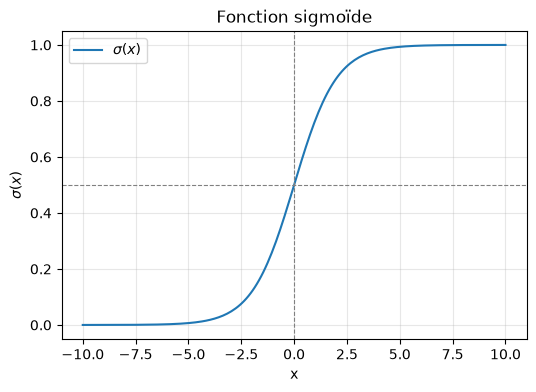

In [7]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

x = np.linspace(-10, 10, 200)

plt.figure(figsize=(6, 4))
plt.plot(x, sigmoid(x), label=r"$\sigma(x)$")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Fonction sigmoïde")
plt.xlabel("x")
plt.ylabel(r"$\sigma(x)$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()